# QFF2026 QML Track — PS-Q2 solution: noisy ZZ-ring quantum-kernel SVM

1. Setup and environment check
2. Task A: Bell state fidelity (official benchmark code)
3. Task B: Processor D validation and QFT-3 benchmark
4. PS-Q2: classical baselines and quantum feature-map ablation (saved grids)
5. PS-Q2: submitted model — noisy QFF2026-v2 kernel on a 300-sample subset → `predictions_q2.csv`
6. PS-Q2: evaluation metrics — ideal vs noisy vs classical on identical folds, and the signal lost to noise (reported, not mitigated)
7. Validate the predictions file

Run from the project root. All seeds are 42. The expensive noisy steps resume from the checkpoints in `results/tables/`. Set the flags below to `True` to recompute them from scratch.

In [1]:
RECOMPUTE_GRIDS = False      # True: rerun classical (204) + quantum ablation (168) grids, ~minutes
RECOMPUTE_NOISY_CV = False   # True: rerun 5-fold noisy CV, 216,600 circuits, ~5 h
# The submitted noisy kernel (105,150 circuits) always runs through run_step6_noisy_test.main(), which
# resumes from checkpoints: if they are complete, no circuits are re-simulated.

import sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd()
assert (ROOT / "noise_model" / "benchmark_noise_model.py").exists(), "run the notebook from the project root"
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "benchmark"))
TABLES = ROOT / "results" / "tables"
SEED = 42
np.random.seed(SEED)

import qiskit, qiskit_aer, sklearn
from noise_model.benchmark_noise_model import get_noise_params
print("python", sys.version.split()[0], "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)
print(get_noise_params())

python 3.12.9 | qiskit 2.3.0 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | numpy 2.4.6
{'single_qubit_depolarizing': 0.01, 'two_qubit_depolarizing': 0.05, 'readout_error': 0.02, 'noisy_1q_gates': ['rx', 'ry', 'rz', 'h', 'x', 'y', 'z', 's', 'sdg', 't', 'tdg', 'sx'], 'noisy_2q_gates': ['cx', 'cz', 'swap'], 'default_basis': ['rx', 'ry', 'rz', 'cx'], 'simulator': 'qiskit-aer AerSimulator', 'version': 'QFF2026-v2'}


## 2. Task A — Bell state |Φ+⟩
F = (1 + ⟨XX⟩ − ⟨YY⟩ + ⟨ZZ⟩)/4 from parity correlators, 8192 shots per basis, via `task_a_bell()`.

In [2]:
from qff_qml_benchmark import task_a_bell
task_a = task_a_bell()
(TABLES / "task_a_bell.json").write_text(json.dumps(task_a, indent=2))
pd.DataFrame({c: task_a[c] for c in ("ideal", "noisy")}).T.round(4)

,XX,XX_se,YY,YY_se,ZZ,ZZ_se,fidelity,fidelity_se
ideal,1.0000,0.0000,-1.0000,0.0000,1.0000,0.0000,1.0000,0.0000
noisy,0.8191,0.0063,-0.8279,0.0062,0.8735,0.0054,0.8801,0.0026


## 3. Task B — Processor D (6-qubit 2×3 grid, two-way links)
The topology was chosen with `run_processor_d_sweep.py` (`results/tables/processor_d_topology_sweep.csv`). Here we validate the config and re-run the official QFT-3 benchmark.

In [3]:
from qff_qml_benchmark import load_processor_d, validate_processor_d, task_b_qft3
cfg = load_processor_d(str(ROOT / "processor_d_config.json"))
problems = validate_processor_d(cfg)
assert not problems, problems
task_b = task_b_qft3(cfg)
assert all(cfg["benchmark_results"][k] == v for k, v in task_b.items()), "config benchmark_results out of date"
print(json.dumps(task_b, indent=2))
pd.read_csv(TABLES / "processor_d_topology_sweep.csv")[["topology", "qft3_fidelity_noisy", "qft3_circuit_depth_after_transpile",
                                                      "q2_ring_depth_after_transpile", "q2_ring_cx_count"]]

{
  "qft3_circuit_depth_before_transpile": 6,
  "qft3_circuit_depth_after_transpile": 21,
  "qft3_two_qubit_gate_count": 12,
  "qft3_swap_overhead": 1,
  "qft3_fidelity_ideal": 1.0,
  "qft3_fidelity_noisy": 0.626784,
  "benchmark_noise_model_version": "QFF2026-v2"
}


,topology,qft3_fidelity_noisy,qft3_circuit_depth_after_transpile,q2_ring_depth_after_transpile,q2_ring_cx_count
0,linear,0.603585,22,59,46
1,ring,0.603585,22,41,24
2,star,0.603585,22,57,36
3,grid2x3,0.626784,21,41,24


Trade-off check on our own circuit: the same grid with two-way vs one-way links (direction is enforced by the benchmark).

In [4]:
subprocess.run([sys.executable, "run_processor_d_direction.py"], check=True, capture_output=True)
pdd = json.loads((TABLES / "processor_d_direction.json").read_text())
pd.DataFrame({k: {"directed edges": v["directed_edges"], "QFT-3 depth": v["qft3"]["qft3_circuit_depth_after_transpile"],
                  "QFT-3 noisy F": v["qft3"]["qft3_fidelity_noisy"], "Q2 kernel depth": v["q2_depth"],
                  "Q2 kernel CX": v["q2_cx"], "Q2 SWAP CX overhead": v["q2_swap_overhead_cx"]}
              for k, v in pdd.items() if k != "q2_circuit_all_to_all"}).T

,directed edges,QFT-3 depth,QFT-3 noisy F,Q2 kernel depth,Q2 kernel CX,Q2 SWAP CX overhead
two_way,14.0,21.0,0.626784,41.0,24.0,0.0
one_way,7.0,31.0,0.585432,51.0,24.0,0.0


## 4. PS-Q2 — model selection on training data only
Classical SVM grid (`run_step2_baselines.py`) and quantum feature-map ablation (`run_step4_ablation.py`). Both use fold-correct repeated stratified CV with balanced accuracy.

In [5]:
if RECOMPUTE_GRIDS:
    subprocess.run([sys.executable, "run_step2_baselines.py"], check=True)
    subprocess.run([sys.executable, "run_step4_ablation.py"], check=True)
cg = pd.read_csv(TABLES / "classical_grid.csv")
qg = pd.read_csv(TABLES / "quantum_ablation_grid.csv")
print("Best classical per family:")
display(cg.sort_values("cv_mean", ascending=False).groupby("family").head(1).round(4))
print("Best quantum config per map/topology (product = no-entanglement control):")
display(qg.sort_values("cv_mean", ascending=False).groupby(["map", "topology"]).head(1).round(4))
print("Kernel-concentration check, ZZ-ring k=6 reps=1: bandwidth s vs CV accuracy and off-diagonal std of K")
zr = qg[(qg["map"] == "zz") & (qg["topology"] == "ring") & (qg["k"] == 6) & (qg["reps"] == 1)]
display(zr[["s", "best_C", "cv_mean", "cv_std", "offdiag_std", "alignment"]].round(4))

Best classical per family:


,family,dim,C,gamma,degree,cv_mean,cv_std
76,RBF-SVM,PCA-6,1.0,0.03,NaN,0.7280,0.0231
97,Poly-SVM,PCA-6,10.0,scale,2.0,0.7253,0.0300
100,Linear-SVM,PCA-6,0.3,NaN,NaN,0.7089,0.0243


Best quantum config per map/topology (product = no-entanglement control):


,map,topology,k,reps,s,best_C,cv_mean,cv_std,offdiag_std,alignment
23,product,-,6,2,0.35,3.0,0.7304,0.0324,0.1125,0.0108
105,zz,all,6,2,0.10,30.0,0.7291,0.0214,0.0166,0.0023
58,zz,ring,6,1,0.35,1.0,0.7286,0.0291,0.1477,0.0143
147,reup,ring,6,2,0.10,30.0,0.7281,0.0310,0.0314,0.0034


Kernel-concentration check, ZZ-ring k=6 reps=1: bandwidth s vs CV accuracy and off-diagonal std of K


,s,best_C,cv_mean,cv_std,offdiag_std,alignment
56,0.10,30.0,0.7129,0.0254,0.0167,0.0023
57,0.20,10.0,0.7233,0.0272,0.0618,0.0056
58,0.35,1.0,0.7286,0.0291,0.1477,0.0143
59,0.50,0.3,0.7236,0.0357,0.1956,0.0249
60,0.75,0.3,0.6990,0.0321,0.1579,0.0338
61,1.00,0.3,0.6529,0.0424,0.0947,0.0316
62,1.50,3.0,0.5536,0.0382,0.0407,0.0296


## 5. Submitted model — noisy ZZ-ring kernel (k=6, reps=1, s=0.35, C=1)
- Encoding: StandardScaler, then PCA(6) and a unit-variance rescale, fitted on the 800 training rows only. Test rows are only transformed.
- Training subset: 150 A + 150 B, fixed by `stratified_subset(y, 300, seed=42)`.
- Kernel entries: P(0…0) of U(x′)†U(x) transpiled to rx/ry/rz/cx and run under QFF2026-v2, with 4096 shots. That is 45,150 train circuits plus 60,000 test circuits.
- No noise mitigation.

In [6]:
import run_step6_noisy_test as s6
s6.main()
pred = pd.read_csv(ROOT / "predictions_q2.csv")
pred.label.value_counts()

Resuming noisy_train: 90000 / 90000 matrix cells already checkpointed


Resuming noisy_test: 60000 / 60000 matrix cells already checkpointed



Noisy subset prediction run complete.
{
  "tag": "zz_ring_k6_r1_n300",
  "map": "zz",
  "topology": "ring",
  "k": 6,
  "reps": 1,
  "s": 0.35,
  "n_sub": 300,
  "subset_idx_seed": 42,
  "class_counts": {
    "A": 150,
    "B": 150
  },
  "shots": 4096,
  "noise_model_version": "QFF2026-v2",
  "C_frozen_from_existing_noisy_CV": 1.0,
  "train_kernel_expected_circuits": 45150,
  "test_kernel_expected_circuits": 60000,
  "note": "Train subset and official test cross-kernel; PCA/scaler fitted on all labeled training features only. Test labels are not accessed.",
  "train_kernel_shape": [
    300,
    300
  ],
  "test_kernel_shape": [
    200,
    300
  ],
  "train_kernel_mean_diagonal": 0.31689128279685974,
  "train_kernel_mean_offdiagonal": 0.22811703383922577,
  "train_kernel_offdiagonal_std": 0.041785579174757004,
  "prediction_counts": {
    "A": 121,
    "B": 79
  },
  "prediction_file": "predictions_q2.csv",
  "status": "complete",
  "completed_at_epoch": 1793296599.282239
}
Predict

label
A    121
B     79
Name: count, dtype: int64

In [7]:
from src.qkernel import feature_map_ops, fidelity_circuit
from src.noisy_kernel import compile_noisy
from src.q2_data import load_q2
from src.qcv import encode
X, y, X_test, test_ids = load_q2()
Z = encode(X, [X], 6)[0]
c = compile_noisy([fidelity_circuit(feature_map_ops("zz", 6, 1, 0.35, "ring"), 6, Z[0], Z[1])])[0]
print("fidelity circuit after transpile: depth", c.depth(), "| ops", dict(c.count_ops()))
c.draw(output="text", fold=-1)

fidelity circuit after transpile: depth 41 | ops {'rz': 24, 'cx': 24, 'ry': 12, 'measure': 6, 'barrier': 1}


┌──────────┐┌─────────────┐                                                                                                                                 ┌───┐┌──────────────┐┌───┐ ░ ┌───┐┌──────────────┐┌───┐                                                                                                                                                                          ┌─────────────┐┌─────────┐┌─┐   
q_0: ┤ Ry(-π/2) ├┤ Rz(-2.5072) ├──■───────────────────■──────────────────────────────────────────────────────────────────────────────────────────────────────────┤ X ├┤ Rz(-0.12808) ├┤ X ├─░─┤ X ├┤ Rz(-0.04904) ├┤ X ├────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────■──────────────────────────■──┤ Rz(-2.8797) ├┤ Ry(π/2) ├┤M├───
     ├──────────┤├─────────────┤┌─┴─┐┌─────────────┐┌─┴─┐                                                                                                        └─┬─┘└──────────────┘└─┬─┘ ░ └─┬─┘└──────────────┘└─┬─┘                                                                                                                                          ┌─┴─┐     ┌───────────────┐┌─┴─┐├─────────────┤├─────────┤└╥┘┌─┐
q_1: ┤ Ry(-π/2) ├┤ Rz(-2.1827) ├┤ X ├┤ Rz(0.60832) ├┤ X ├──■───────────────────■───────────────────────────────────────────────────────────────────────────────────┼────────────────────┼───░───┼────────────────────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────■─────────────────────────■──────┤ X ├─────┤ Rz(-0.078555) ├┤ X ├┤ Rz(-2.8417) ├┤ Ry(π/2) ├─╫─┤M├
     ├──────────┤├─────────────┤└───┘└─────────────┘└───┘┌─┴─┐┌─────────────┐┌─┴─┐                                                                                 │                    │   ░   │                    │                                                                                                         ┌─┴─┐     ┌──────────────┐┌─┴─┐┌───┴───┴────┐└──┬─────────┬──┘└┬─┬┘└─────────────┘└─────────┘ ║ └╥┘
q_2: ┤ Ry(-π/2) ├┤ Rz(-2.6269) ├─────────────────────────┤ X ├┤ Rz(0.49354) ├┤ X ├──■─────────────────────■────────────────────────────────────────────────────────┼────────────────────┼───░───┼────────────────────┼───────────────────────────────────────────────────────────────────────■─────────────────────────■───────┤ X ├─────┤ Rz(0.085551) ├┤ X ├┤ Rz(2.8564) ├───┤ Ry(π/2) ├────┤M├────────────────────────────╫──╫─
     ├──────────┤└┬────────────┤                         └───┘└─────────────┘└───┘┌─┴─┐┌───────────────┐┌─┴─┐                                                      │                    │   ░   │                    │                                                                     ┌─┴─┐     ┌──────────────┐┌─┴─┐┌────┴───┴────┐└─┬─────────┬──┘└┬─┬┘└────────────┘   └─────────┘    └╥┘                            ║  ║ 
q_3: ┤ Ry(-π/2) ├─┤ Rz(3.1213) ├──────────────────────────────────────────────────┤ X ├┤ Rz(-0.010465) ├┤ X ├──■────────────────────■──────────────────────────────┼────────────────────┼───░───┼────────────────────┼────────────────────────────────────■─────────────────────────■──────┤ X ├─────┤ Rz(0.064014) ├┤ X ├┤ Rz(-2.9172) ├──┤ Ry(π/2) ├────┤M├──────────────────────────────────╫─────────────────────────────╫──╫─
     ├──────────┤ ├────────────┤                                                  └───┘└───────────────┘└───┘┌─┴─┐┌──────────────┐┌─┴─┐                            │                    │   ░   │                    │                                  ┌─┴─┐     ┌──────────────┐┌─┴─┐┌───┴───┴────┐└─┬─────────┬──┘└┬─┬┘└─────────────┘  └─────────┘    └╥┘                                  ║                             ║  ║ 
q_4: ┤ Ry(-π/2) ├─┤ Rz(3.0749) ├─────────────────────────────────────────────────────────────────────────────┤ X ├┤ Rz(0.001357) ├┤ X ├──■────────────────────■────┼────────────────────┼───░───┼────────────────────┼────■───────────────

## 6. Evaluation metrics and the signal lost to noise
`run_step7_noisy_cv_metrics.py` gives fold-correct 5-fold CV of the noisy kernel (216,600 circuits). `run_step7_classical_cv_metrics.py` and `run_step9_kernel_metrics.py` evaluate the classical RBF and the ideal kernel on **the same 300 rows and the same folds**. Step 9 also measures how much kernel signal the noise removes. The loss is reported as a negative result; nothing is mitigated.

In [8]:
if RECOMPUTE_NOISY_CV:
    subprocess.run([sys.executable, "run_step7_noisy_cv_metrics.py"], check=True)
subprocess.run([sys.executable, "run_step7_classical_cv_metrics.py"], check=True, capture_output=True)
import run_step9_kernel_metrics as s9
s9.main()

                                                      model   n  accuracy  balanced_accuracy  precision_B  recall_B   f1_B  f1_macro  roc_auc  fold_bal_acc_mean  fold_bal_acc_std         bal_acc_ci95                                                                                                                     chosen_params
                Quantum ZZ-ring kernel, ideal (statevector) 300    0.7033             0.7033       0.7163    0.6733 0.6942    0.7031   0.7627             0.7033            0.0427 [0.650405, 0.755935]                                                                                                                               NaN
     Quantum ZZ-ring kernel, noisy (QFF2026-v2, 4096 shots) 300    0.6867             0.6867       0.6867    0.6867 0.6867    0.6867      NaN             0.6867            0.0323 [0.633269, 0.741085]                                                                                                                               NaN
          

In [9]:
km = json.loads((TABLES / "kernel_metrics_zz_ring_k6_r1_n300.json").read_text())
tab = pd.DataFrame(km["subset_n300_same_folds"] + km["all_800_context"]).set_index("model")
display(tab[["n", "balanced_accuracy", "bal_acc_ci95", "fold_bal_acc_std", "precision_B", "recall_B", "f1_B", "roc_auc"]].round(4))
display(pd.DataFrame(km["paired_noise_effect"]["bootstrap_paired_differences"]).T)
p = km["paired_noise_effect"]
print(f"Paired noisy - ideal balanced accuracy: {p['noisy_minus_ideal_mean']:+.4f} +/- {p['noisy_minus_ideal_se']:.4f} (SE, 5 folds)")
L = km["kernel_signal_loss_n300"]
print(f"Kernel contrast (off-diagonal std): ideal {L['offdiag_std_ideal']:.3f} -> noisy {L['offdiag_std_noisy']:.3f} "
      f"({L['offdiag_std_noisy']/L['offdiag_std_ideal']-1:+.0%}); diagonal {L['diag_noisy_mean']:.3f}; "
      f"affine fit {L['affine_slope']:.3f}x+{L['affine_intercept']:.3f} (R2={L['affine_R2']:.3f}); "
      f"residual after affine fit {L['rel_error_after_affine_fit']:.1%}")

,n,balanced_accuracy,bal_acc_ci95,fold_bal_acc_std,precision_B,recall_B,f1_B,roc_auc
model,,,,,,,,
"Quantum ZZ-ring kernel, ideal (statevector)",300,0.7033,"[0.650405, 0.755935]",0.0427,0.7163,0.6733,0.6942,0.7627
"Quantum ZZ-ring kernel, noisy (QFF2026-v2, 4096 shots)",300,0.6867,"[0.633269, 0.741085]",0.0323,0.6867,0.6867,0.6867,NaN
"Classical RBF-SVM (PCA-6, C=1, gamma=scale)",300,0.6833,"[0.627019, 0.735851]",0.0380,0.7099,0.6200,0.6619,NaN
"Classical RBF-SVM, tuned in each training fold (nested CV)",300,0.6933,"[0.639995, 0.744937]",0.0374,0.7132,0.6467,0.6783,0.7553
"Classical poly-SVM, tuned in each training fold (nested CV)",300,0.7167,"[0.666383, 0.769034]",0.0333,0.7407,0.6667,0.7018,0.7705
"Quantum ZZ-ring kernel, ideal, n=800",800,0.7368,NaN,0.0263,0.7570,0.7222,0.7392,0.8077
"Classical RBF-SVM (PCA-6, C=1, gamma=scale), n=800",800,0.7300,NaN,0.0196,0.7438,0.7295,0.7366,0.8031


,mean,ci95,p_le_0
noisy_minus_ideal,-0.016402,"[-0.047794, 0.015704]",0.845
noisy_minus_rbf_tuned,-0.006794,"[-0.040743, 0.026678]",0.667
ideal_minus_rbf_tuned,0.009608,"[-0.016604, 0.037509]",0.238
noisy_minus_rbf_default,0.003403,"[-0.037228, 0.043334]",0.432
noisy_minus_poly_tuned,-0.029883,"[-0.067659, 0.007874]",0.939
ideal_minus_poly_tuned,-0.013482,"[-0.047102, 0.018654]",0.7975


Paired noisy - ideal balanced accuracy: -0.0167 +/- 0.0139 (SE, 5 folds)
Kernel contrast (off-diagonal std): ideal 0.147 -> noisy 0.042 (-72%); diagonal 0.317; affine fit 0.280x+0.040 (R2=0.976); residual after affine fit 15.6%


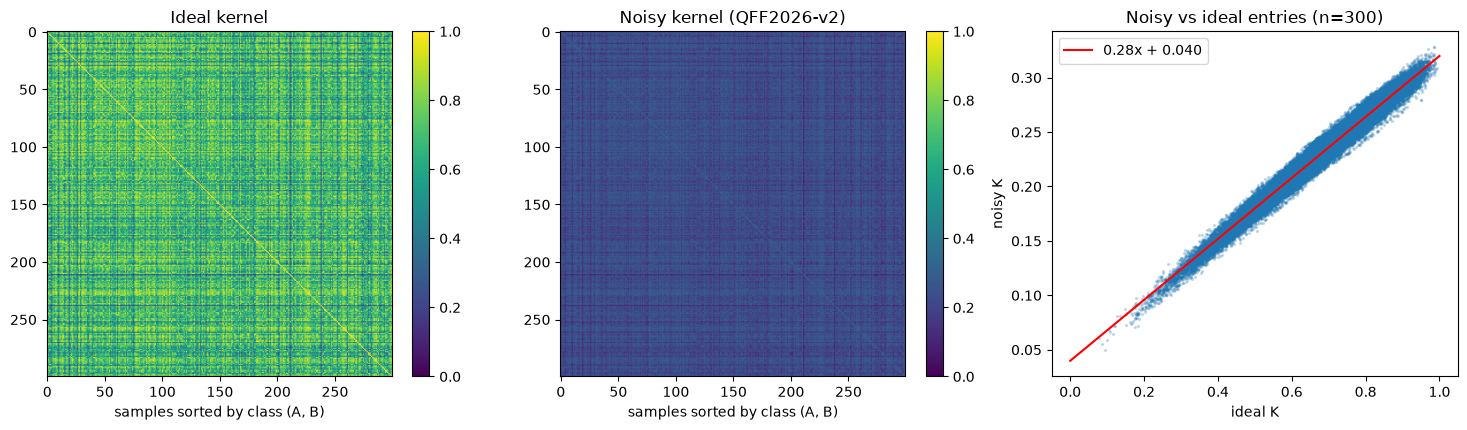

In [10]:
import matplotlib.pyplot as plt
from src.qkernel import batched_states, kernel_from_states
from src.q2_data import stratified_subset
sub = stratified_subset(y, 300)
S = batched_states(feature_map_ops("zz", 6, 1, 0.35, "ring"), Z[sub], 6)
Ki, Kn = kernel_from_states(S, S), np.load(TABLES / "K_noisy_train_zz_ring_k6_r1_n300.npy")
o = np.argsort(y[sub], kind="stable"); m = ~np.eye(300, dtype=bool)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, M, t in [(ax[0], Ki, "Ideal kernel"), (ax[1], Kn, "Noisy kernel (QFF2026-v2)")]:
    im = a.imshow(M[np.ix_(o, o)], vmin=0, vmax=1); a.set_title(t); a.set_xlabel("samples sorted by class (A, B)")
    fig.colorbar(im, ax=a, fraction=0.046)
ax[2].scatter(Ki[m], Kn[m], s=2, alpha=0.1); xs = np.linspace(0, 1, 50)
ax[2].plot(xs, L["affine_slope"] * xs + L["affine_intercept"], "r-", label=f"{L['affine_slope']:.2f}x + {L['affine_intercept']:.3f}")
ax[2].set_xlabel("ideal K"); ax[2].set_ylabel("noisy K"); ax[2].set_title("Noisy vs ideal entries (n=300)"); ax[2].legend()
fig.tight_layout(); fig.savefig(ROOT / "results" / "figures" / "noise_effect_zz_ring_k6_r1_n300.png", dpi=150); plt.show()

**Negative result.** Noise contracts the kernel to about 28% of its ideal scale. A constant shift does not change the SVM, and a scale factor only rescales C, so most of this contraction is harmless. The ≈16% non-affine residual (non-uniform noise and shot noise) is real information loss. It costs about 1.6 points of balanced accuracy on paired folds. The noisy model (0.687) is level with a classical RBF-SVM tuned on the same training folds (0.693). It is below a tuned degree-2 polynomial SVM (0.717). No quantum advantage is shown. Full discussion: `results.md`.

## 7. Validate the submission file

In [11]:
r = subprocess.run([sys.executable, "tools/validate_predictions.py", "q2", "predictions_q2.csv"], capture_output=True, text=True)
print(r.stdout, r.stderr); assert r.returncode == 0

OK - predictions file is valid.
 
